<a href="https://colab.research.google.com/github/Shihabalfaj6062/aiml-lab-problem-1-/blob/main/Different%20Machine%20Learning%20Models%20Applied%20to%20the%20Processed%20Stroke%20Dataset%20and%20do%20the%20Comparative%20Study%20among%20ML%20models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stroke Prediction Model Evaluation
In this notebook, we will train and compare 5 Supervised Machine Learning models (including an Artificial Neural Network) on the processed stroke dataset to predict stroke risk. We will evaluate each using Precision, Recall, F1-Score, Accuracy, AUC-ROC, and Confusion Matrices.

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Set plotting style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [49]:
from google.colab import files
import io
import pandas as pd

print("Please upload your 'stroke_processed_5k.csv' file:")
uploaded = files.upload()

# Find the uploaded file name
for fn in uploaded.keys():
    if fn.endswith('.csv'):
        # Save it to the expected path
        with open('/content/stroke_processed_5k.csv', 'wb') as f:
            f.write(uploaded[fn])
        print(f"\nSuccessfully uploaded and saved '{fn}' as '/content/stroke_processed_5k.csv'")

        # Preview the uploaded data
        df = pd.read_csv('/content/stroke_processed_5k.csv')
        print(f"Uploaded Dataset Shape: {df.shape}")
        display(df.head())
        break
else:
    print("No CSV file detected. Please run the cell again and upload your CSV.")

Please upload your 'stroke_processed_5k.csv' file:


Saving stroke_processed_5k.csv to stroke_processed_5k (1).csv

Successfully uploaded and saved 'stroke_processed_5k (1).csv' as '/content/stroke_processed_5k.csv'
Uploaded Dataset Shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


In [50]:
# Assuming the target column is named 'stroke'. Let's verify and separate features and target.
target_col = 'stroke' if 'stroke' in df.columns else df.columns[-1]
print(f"Using '{target_col}' as target column.")

X = df.drop(columns=[target_col])
y = df[target_col]

# Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the features (important for SVM and ANN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Using 'stroke' as target column.
Training set shape: (4088, 10)
Testing set shape: (1022, 10)


## Model Training & Evaluation Setup
We will now train 5 models:
1. **Logistic Regression**
2. **Random Forest Classifier**
3. **Gradient Boosting Classifier**
4. **Support Vector Machine (SVM)**
5. **Artificial Neural Network (ANN)**

In [51]:
# Dictionary to store performance metrics
metrics_dict = {}
# Dictionary to store ROC curve values
roc_curves = {}

def evaluate_model(model_name, y_true, y_pred, y_probs):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_probs)

    metrics_dict[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC-ROC': auc
    }

    # Calculate ROC Curve points
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_curves[model_name] = (fpr, tpr, auc)

    print(f"=== {model_name} Evaluation ===")
    print(classification_report(y_true, y_pred, zero_division=0))
    print(f"AUC-ROC: {auc:.4f}\n")

    # Confusion Matrix Plot
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No Stroke', 'Stroke'], yticklabels=['No Stroke', 'Stroke'])
    plt.title(f'Confusion Matrix: {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

=== Logistic Regression Evaluation ===
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

AUC-ROC: 0.8377



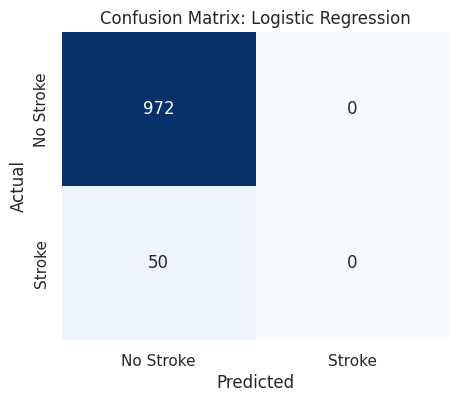

In [52]:
# 1. Logistic Regression
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

evaluate_model('Logistic Regression', y_test, lr_preds, lr_probs)

=== Random Forest Evaluation ===
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       972
           1       0.17      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.56      0.51      0.50      1022
weighted avg       0.91      0.95      0.93      1022

AUC-ROC: 0.8160



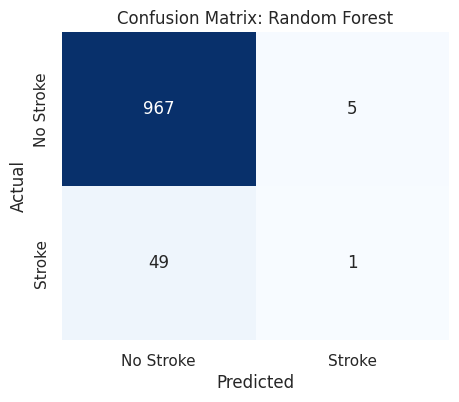

In [53]:
# 2. Random Forest
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train_scaled, y_train)
rf_preds = rf_model.predict(X_test_scaled)
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]

evaluate_model('Random Forest', y_test, rf_preds, rf_probs)

=== Gradient Boosting Evaluation ===
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.40      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.68      0.52      0.52      1022
weighted avg       0.93      0.95      0.93      1022

AUC-ROC: 0.8321



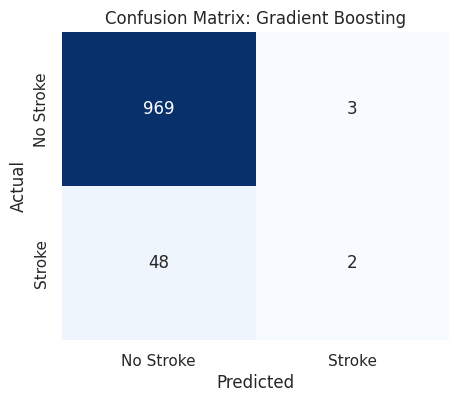

In [54]:
# 3. Gradient Boosting
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train_scaled, y_train)
gb_preds = gb_model.predict(X_test_scaled)
gb_probs = gb_model.predict_proba(X_test_scaled)[:, 1]

evaluate_model('Gradient Boosting', y_test, gb_preds, gb_probs)

=== SVM Evaluation ===
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

AUC-ROC: 0.6108



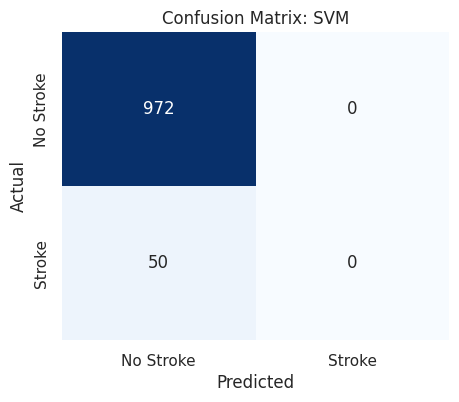

In [55]:
# 4. Support Vector Machine
svm_model = SVC(probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)
svm_preds = svm_model.predict(X_test_scaled)
svm_probs = svm_model.predict_proba(X_test_scaled)[:, 1]

evaluate_model('SVM', y_test, svm_preds, svm_probs)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
=== ANN Evaluation ===
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

AUC-ROC: 0.8403



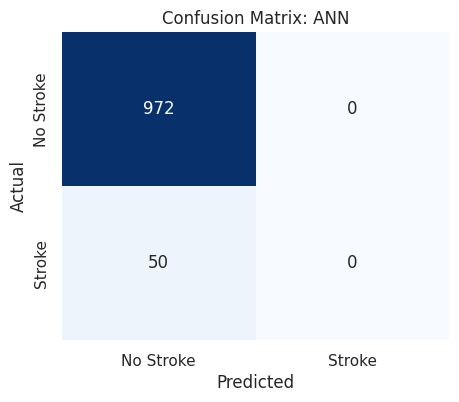

In [56]:
# 5. Artificial Neural Network (ANN)
tf.random.set_seed(42)

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

ann_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = ann_model.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=0
)

ann_probs = ann_model.predict(X_test_scaled).flatten()
ann_preds = (ann_probs > 0.5).astype(int)

evaluate_model('ANN', y_test, ann_preds, ann_probs)

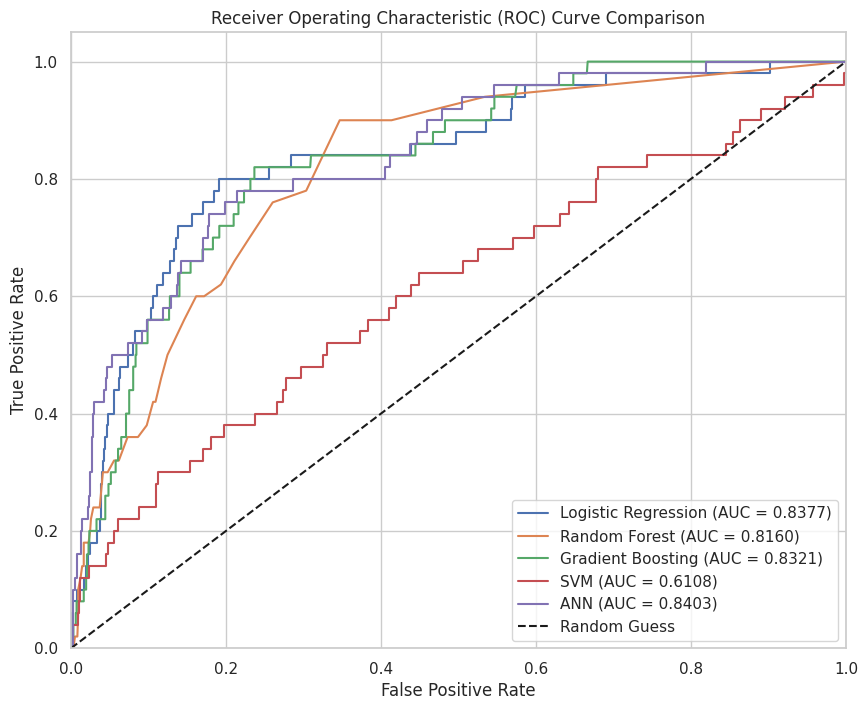

In [57]:
# Plot Combined AUC-ROC Curve
plt.figure(figsize=(10, 8))
for name, (fpr, tpr, auc) in roc_curves.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison')
plt.legend(loc='lower right')
plt.show()

In [58]:
# Compare and Rank Top Models
metrics_df = pd.DataFrame(metrics_dict).T
# Let's sort by AUC-ROC as it provides a comprehensive assessment of model classification power
metrics_df = metrics_df.sort_values(by='AUC-ROC', ascending=False)

print("=== Performance Comparison Matrix ===")
display(metrics_df)

print("\n=== Top 3 Models for Stroke Risk Prediction Analysis ===")
top_3 = metrics_df.head(3)
display(top_3)

=== Performance Comparison Matrix ===


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
ANN,0.951076,0.000000,0.00,0.000000,0.840329
Logistic Regression,0.951076,0.000000,0.00,0.000000,0.837695
Gradient Boosting,0.950098,0.400000,0.04,0.072727,0.832119
Random Forest,0.947162,0.166667,0.02,0.035714,0.816049
SVM,0.951076,0.000000,0.00,0.000000,0.610823



=== Top 3 Models for Stroke Risk Prediction Analysis ===


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
ANN,0.951076,0.0,0.00,0.000000,0.840329
Logistic Regression,0.951076,0.0,0.00,0.000000,0.837695
Gradient Boosting,0.950098,0.4,0.04,0.072727,0.832119
